# 정밀도와 재현율 실습

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/SuminHan/book-ml/blob/main/slides/v2/ml1/week02/precision_recall/lab/precision_recall.ipynb)

쏠린 데이터에서는 정확도가 속는다. 혼동 행렬, 정밀도, 재현율, F1 을 직접 구현하고, 기준선(임계값)을 움직여 본다.

- **파트 1**: 슬라이드의 점수 100개로 혼동 행렬 · 정밀도 · 재현율 · F1 구현
- **파트 2**: 기준을 움직이며 정밀도 · 재현율 줄다리기 그리기
- **파트 3**: 실제 의료 데이터 (피마 인디언 당뇨병 768명): 로지스틱회귀 + 기준 고르기

`None` 으로 비워 둔 `TODO` 줄을 채우고 셀을 차례로 실행하세요.

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt

## 슬라이드의 예시 데이터

학교 100명 중 독감 10명. AI 가 낸 '독감일 확률' 점수.

In [ ]:
# Same example as the slides: AI scores for 10 sick and 90 healthy students
sick = np.array([0.95, 0.91, 0.86, 0.82, 0.77, 0.71, 0.63, 0.56, 0.44, 0.31])
healthy = np.array([0.81, 0.66, 0.58, 0.53, 0.33, 0.32, 0.27, 0.25, 0.25, 0.25, 0.24, 0.21, 0.21, 0.2, 0.2, 0.2, 0.19, 0.19,
                    0.19, 0.17, 0.16, 0.16, 0.16, 0.16, 0.16, 0.16, 0.16, 0.16, 0.15, 0.15, 0.14, 0.14, 0.14, 0.14, 0.14, 0.14,
                    0.13, 0.13, 0.13, 0.13, 0.13, 0.13, 0.12, 0.12, 0.11, 0.11, 0.11, 0.11, 0.1, 0.1, 0.1, 0.1, 0.1, 0.09, 0.09,
                    0.09, 0.09, 0.09, 0.08, 0.08, 0.08, 0.07, 0.07, 0.07, 0.07, 0.07, 0.07, 0.07, 0.07, 0.06, 0.06, 0.06, 0.05,
                    0.05, 0.05, 0.05, 0.05, 0.04, 0.04, 0.04, 0.04, 0.04, 0.04, 0.03, 0.03, 0.03, 0.03, 0.02, 0.02, 0.01])
y_true = np.r_[np.ones(len(sick)), np.zeros(len(healthy))].astype(int)     # 1 = flu
scores = np.r_[sick, healthy]
print(len(scores), "students,", y_true.sum(), "with flu")

**예상 결과**

```
100 students, 10 with flu
```

## 파트 1. 혼동 행렬과 지표

$$\text{precision} = \frac{TP}{TP + FP}, \qquad \text{recall} = \frac{TP}{TP + FN}, \qquad F_1 = \frac{2PR}{P + R}$$

In [ ]:
def confusion(y_true, y_pred):
    tp = np.sum((y_pred == 1) & (y_true == 1))
    fp = None  # TODO: said flu, actually healthy
    fn = None  # TODO: said healthy, actually flu
    tn = np.sum((y_pred == 0) & (y_true == 0))
    return tp, fp, fn, tn

def precision_recall_f1(tp, fp, fn):
    p = None  # TODO: precision
    r = None  # TODO: recall
    f1 = None  # TODO: harmonic mean of p and r
    return p, r, f1

y_pred = (scores >= 0.5).astype(int)
tp, fp, fn, tn = confusion(y_true, y_pred)
p, r, f1 = precision_recall_f1(tp, fp, fn)
print(f"TP={tp} FP={fp} FN={fn} TN={tn}")
print(f"accuracy={(tp + tn) / len(y_true):.2f}  precision={p:.2f}  recall={r:.2f}  F1={f1:.2f}")

**예상 결과**

```
TP=8 FP=4 FN=2 TN=86
accuracy=0.94  precision=0.67  recall=0.80  F1=0.73
```

In [ ]:
# Two lazy 'models': everyone healthy, everyone flu
for name, pred in [("all healthy", np.zeros(100, int)), ("all flu", np.ones(100, int))]:
    tp, fp, fn, tn = confusion(y_true, pred)
    p, r, f1 = precision_recall_f1(tp, fp, fn)
    print(f"{name:12s}: accuracy={(tp + tn) / 100:.2f}  precision={p:.2f}  recall={r:.2f}  F1={f1:.2f}")

from sklearn.metrics import precision_score, recall_score, f1_score
print("sklearn check (threshold 0.5):", precision_score(y_true, y_pred), recall_score(y_true, y_pred), round(f1_score(y_true, y_pred), 3))

**예상 결과**

```
all healthy : accuracy=0.90  precision=0.00  recall=0.00  F1=0.00
all flu     : accuracy=0.10  precision=0.10  recall=1.00  F1=0.18
sklearn check (threshold 0.5): 0.6666666666666666 0.8 0.727
```

## 파트 2. 기준선을 움직이면

기준을 0.05 부터 0.95 까지 움직이며 정밀도와 재현율을 그린다. 슬라이드 표: 0.3 → 62% / 100%, 0.7 → 86% / 60%.

In [ ]:
def sweep(y_true, scores, thresholds):
    P, R = [], []
    for t in thresholds:
        pred = None  # TODO: 1 if score >= t
        p, r, _ = precision_recall_f1(*confusion(y_true, pred)[:3])
        P.append(p); R.append(r)
    return np.array(P), np.array(R)

ths = np.round(np.arange(0.05, 0.96, 0.01), 2)
P, R = sweep(y_true, scores, ths)
plt.plot(ths, P, label="precision"); plt.plot(ths, R, label="recall")
plt.xlabel("threshold"); plt.ylabel("value"); plt.legend(); plt.show()
for t in [0.3, 0.5, 0.7, 0.9]:
    i = int(np.argmin(np.abs(ths - t)))
    print(f"threshold {t}: precision {P[i]:.2f}  recall {R[i]:.2f}")

**예상 결과**

```
threshold 0.3: precision 0.62  recall 1.00
threshold 0.5: precision 0.67  recall 0.80
threshold 0.7: precision 0.86  recall 0.60
threshold 0.9: precision 1.00  recall 0.20
```

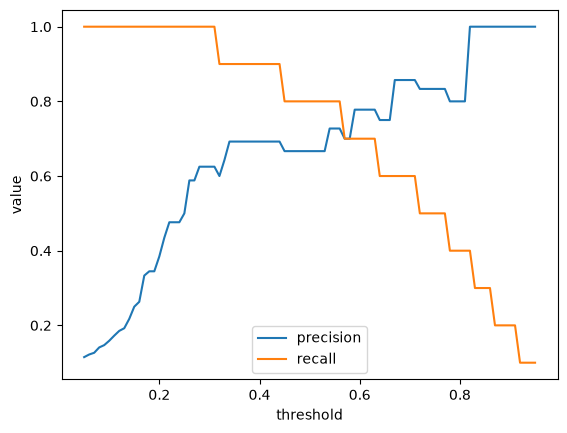

## 파트 3. 실제 데이터: 당뇨병 진단

피마 인디언 당뇨병 데이터: 21세 이상 여성 768명의 혈당, BMI, 나이 등 8가지 검사값과 5년 안 당뇨병 진단 여부(`outcome`). 당뇨병은 약 35%. 처음 실행하면 CSV 를 내려받는다.

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression

url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"
cols = ["pregnancies", "glucose", "blood_pressure", "skin_thickness", "insulin", "bmi", "pedigree", "age", "outcome"]
os.makedirs("data", exist_ok=True)
if not os.path.exists("data/pima.csv"):
    import urllib.request; urllib.request.urlretrieve(url, "data/pima.csv")
df = pd.read_csv("data/pima.csv", header=None, names=cols)
print(len(df), "patients, diabetes rate", round(df["outcome"].mean(), 3))
df.head()

**예상 결과**

```
768 patients, diabetes rate 0.349
   pregnancies  glucose  blood_pressure  skin_thickness  insulin   bmi  \
0            6      148              72              35        0  33.6   
1            1       85              66              29        0  26.6   
2            8      183              64               0        0  23.3   
3            1       89              66              23       94  28.1   
4            0      137              40              35      168  43.1   

   pedigree  age  outcome  
0     0.627   50        1  
1     0.351   31        0  
2     0.672   32        1  
3     0.167   21        0  
4     2.288   33        1  
```

In [ ]:
X, y = df[cols[:-1]].to_numpy(float), df["outcome"].to_numpy()
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.3, random_state=0, stratify=y)
model = make_pipeline(StandardScaler(), LogisticRegression()).fit(X_tr, y_tr)
s_te = model.predict_proba(X_te)[:, 1]                 # probability of diabetes on the test set

print(f"'all healthy' accuracy: {np.mean(y_te == 0):.3f}")
tp, fp, fn, tn = confusion(y_te, (s_te >= 0.5).astype(int))
p, r, f1 = precision_recall_f1(tp, fp, fn)
print(f"threshold 0.5: TP={tp} FP={fp} FN={fn} TN={tn}  accuracy={(tp + tn) / len(y_te):.3f}  precision={p:.2f}  recall={r:.2f}")

**예상 결과**

```
'all healthy' accuracy: 0.649
threshold 0.5: TP=45 FP=16 FN=36 TN=134  accuracy=0.775  precision=0.74  recall=0.56
```

In [ ]:
# Screening: we want recall >= 0.8. Find the highest threshold that reaches it.
ths = np.round(np.arange(0.05, 0.96, 0.01), 2)
P, R = sweep(y_te, s_te, ths)
ok = ths[R >= 0.8]
best = None  # TODO: highest threshold with recall >= 0.8
i = int(np.argmin(np.abs(ths - best)))
print(f"threshold {best}: precision {P[i]:.2f}  recall {R[i]:.2f}")
plt.plot(ths, P, label="precision"); plt.plot(ths, R, label="recall"); plt.axvline(best, ls="--", color="gray")
plt.xlabel("threshold"); plt.legend(); plt.show()

**예상 결과**

```
threshold 0.31: precision 0.67  recall 0.81
```

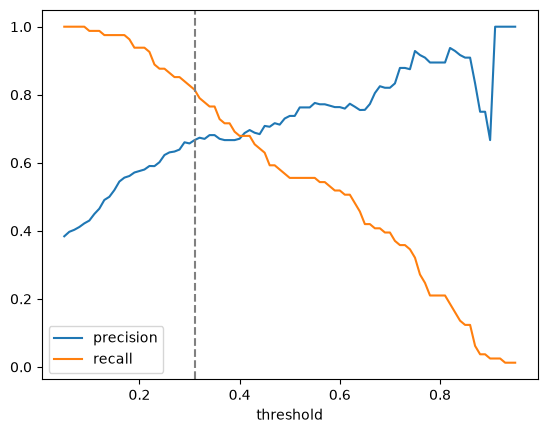

**확인 질문**
1. 파트 1 에서 '모두 독감' 의 F1 이 낮은 이유는? 그냥 평균이었다면?
2. 파트 3 에서 기준 0.5 의 정확도와 '모두 건강' 의 정확도를 비교해 보자. 정확도만 보면 이 모델이 얼마나 나아 보이나?
3. 당뇨병 선별 검사라면 재현율을 우선하는 게 맞을까? 기준을 낮췄을 때 늘어나는 FP 는 실제로 무엇을 뜻하나?
4. (도전) `sklearn.metrics.confusion_matrix` 로 파트 3 의 혼동 행렬을 다시 구해 보고, 행과 열의 순서가 슬라이드와 어떻게 다른지 확인하자.

데이터 출처: Pima Indians Diabetes Database, National Institute of Diabetes and Digestive and Kidney Diseases (UCI 사본).